# Rainbow bank-quote gap — correlation profiles: what the history supports and what it buys

**Question (user, 2026-10-22 → 2026-10-27).** Banks quote the ATM basket call
~25 bps of notional *above* our model and the 112% cap call ~25 bps *below*
it. Every symmetric knob (correlation level, vol level, forwards) moves both
legs the same way, so only an **asymmetric dependence structure** — more
correlation in sell-offs than in rallies — can reproduce the sign pattern.
How much of the gap does a correlation profile that the history actually
supports explain?

**Construct.** One-factor Gaussian copula whose loadings depend on the common
market factor *W* (Andersen–Sidenius random factor loadings):

$$Z_i = a_i(W)\,W + \sqrt{1-a_i(W)^2}\,\varepsilon_i,\qquad
\rho_{ij}(W) = a_i(W)\,a_j(W),$$

with *W*, ε iid N(0,1). The raw scores are no longer normal, so their exact
CDF is tabulated by quadrature over *W* and applied before each index's
implied-marginal quantile: **the three risk-neutral marginals are untouched,
only the copula changes.** A constant profile is the plain Gaussian copula.
For three indices any positive pairwise target is reached exactly by
$a_i=\sqrt{\rho_{ij}\rho_{ik}/\rho_{jk}}$, so "the correlation matrix on the
down side / up side" is a literal input.

| profile | shape | parameters |
|---|---|---|
| **step** | one matrix below a factor threshold θ, another above | ρ_down, ρ_up (SPX–SX5E; other pairs shifted by the same amount), θ |
| **tanh** | a·(1 − λ tanh W): correlation keeps falling the further up the market goes | λ |
| **sigmoid** | plateau through the middle, per-index down-tail lift below c_dn and up-tail cut above c_up, common width | λ_dn,i, λ_up,i, c_dn, c_up, width — **fit to the 21-day binned profile** |

The sigmoid is calibrated twice because the level convention matters: pinned
to the 21-day *Pearson* log-return matrix (what `historical_corr(spots, 21)`
returns, 0.82 on SPX–SX5E), or fit level-and-shape to the 21-day *normal
scores* (rank correlation 0.74). The gap between the two is the COVID
co-crash inflating Pearson — precisely the tail dependence the profile models.

Analysis-only notebook: prices come from the caches written by
`scripts/run_rainbow_corr_regime.py` (the (ρ_down, ρ_up) grid, ~1.5 min) and
`scripts/run_rainbow_corr_profile.py` (the two sigmoid fits and the four-row
table, ~6 min); the realized-profile statistics are cheap and recomputed here.
Changelog: the two 2026-10-27 entries.

In [1]:
import time
T0 = time.time()
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import norm, qmc
from vol_pca.data import load_surfaces
from vol_pca.rainbow import (historical_corr, one_factor_loadings, profile_uniforms,
                             sigmoid_profile, spot_panel, step_profile, tanh_profile)

NAMES = ("SPX", "SX5E", "HSI")
PAIRS = [(0, 1), (0, 2), (1, 2)]
PAIR_LAB = ["SPX–SX5E", "SPX–HSI", "SX5E–HSI"]
sds = {n: load_surfaces(f"{n}_volSurface.csv") for n in NAMES}
spots = spot_panel(sds)
lr = np.log(spots)
regime = pd.read_csv("data/rainbow_corr_regime.csv")
prof = pd.read_csv("data/rainbow_corr_profile.csv")
fit = json.load(open("data/rainbow_corr_profile_fit.json"))

# palette: fixed categorical order (never cycled), text in ink tokens, recessive chrome
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.titlecolor": INK, "axes.titlesize": 10.5, "font.size": 9,
                     "legend.frameon": False, "figure.dpi": 110})

def scores(r):
    """normal scores (rank transform) of a (n, 3) return panel"""
    return norm.ppf((r.argsort(0).argsort(0) + 0.5) / len(r))

def pair_corr(z):
    return np.corrcoef(z.T)[[0, 0, 1], [1, 2, 2]]

def binned_corr(z, n_bins=5):
    """pair correlations of normal scores inside quantile bins of the mean score (the market move)"""
    w = z.mean(1)
    edges = np.quantile(w, np.linspace(0, 1, n_bins + 1))
    b = np.clip(np.searchsorted(edges[1:-1], w, side="right"), 0, n_bins - 1)
    out, wm = np.zeros((n_bins, 3)), np.zeros(n_bins)
    for k in range(n_bins):
        m = b == k
        wm[k] = w[m].mean()
        out[k] = [np.corrcoef(z[m, i], z[m, j])[0, 1] for i, j in PAIRS]
    return out, wm

def half_split(z):
    w = z.mean(1)
    dn = np.array([np.corrcoef(z[w < 0, i], z[w < 0, j])[0, 1] for i, j in PAIRS])
    up = np.array([np.corrcoef(z[w >= 0, i], z[w >= 0, j])[0, 1] for i, j in PAIRS])
    return dn, up

HORIZONS = (5, 21, 63)
rows = []
for h in HORIZONS:
    r = lr.diff(h).dropna().values
    pe, rk = historical_corr(spots, h).values[[0, 0, 1], [1, 2, 2]], pair_corr(scores(r))
    for lab, p_, k_ in zip(PAIR_LAB, pe, rk):
        rows.append({"horizon (days)": h, "pair": lab, "Pearson (log returns)": p_, "rank (normal scores)": k_,
                     "Pearson − rank": p_ - k_})
uncond = pd.DataFrame(rows).set_index(["horizon (days)", "pair"]).round(3)
print(f"{len(spots)} joint dates {spots.index[0].date()} → {spots.index[-1].date()}")
uncond

1969 joint dates 2018-12-27 → 2026-07-31


Pearson (log returns)  rank (normal scores)  \
horizon (days) pair                                                    
5              SPX–SX5E                  0.751                 0.717   
               SPX–HSI                   0.429                 0.426   
               SX5E–HSI                  0.478                 0.479   
21             SPX–SX5E                  0.823                 0.743   
               SPX–HSI                   0.427                 0.408   
               SX5E–HSI                  0.501                 0.492   
63             SPX–SX5E                  0.765                 0.687   
               SPX–HSI                   0.396                 0.399   
               SX5E–HSI                  0.522                 0.530   

                         Pearson − rank  
horizon (days) pair                      
5              SPX–SX5E           0.034  
               SPX–HSI            0.003  
               SX5E–HSI          -0.001  
21             SPX–SX5E           0.080  
               SPX–HSI            0.020  
               SX5E–HSI           0.009  
63             SPX–SX5E           0.077  
               SPX–HSI           -0.003  
               SX5E–HSI          -0.008

## A. The realized correlation profile

**The statistic.** Normal scores of overlapping *h*-day log returns (so fat
marginals cannot masquerade as dependence), the mean score as the market
move, and the pair correlation *inside* each quintile bin of that move. The
conditioning distorts within-bin correlations — fixing the mean of three
scores makes their deviations negatively correlated, so the middle bins of a
*Gaussian* copula read −0.6 on the HSI pairs. The signal is therefore the
**excess over a Gaussian copula under the same binning**, simulated at the
data's own rank correlation. Bands are a 126-day block bootstrap (±1 sd).

The level question shows up already in the unconditional table above:
Pearson and rank agree at 5 days, but at 21 days the SPX–SX5E Pearson
correlation is 0.08 above the rank correlation of the same returns. A few
very large joint moves (March 2020) carry Pearson; the copula sees only
their ranks.

,bin mean W,SPX–SX5E excess,SPX–HSI excess,SX5E–HSI excess,SPX–SX5E sd,SPX–HSI sd,SX5E–HSI sd
21-day quintile,,,,,,,
0,-1.20,0.26,0.32,0.26,0.12,0.16,0.16
1,-0.39,-0.03,0.01,0.01,0.17,0.08,0.10
2,0.04,-0.12,0.04,0.02,0.16,0.07,0.10
3,0.43,-0.05,-0.04,-0.01,0.16,0.06,0.10
4,1.13,-0.00,-0.15,-0.03,0.07,0.08,0.10


half-sample correlations (split on the sign of the market move):


,5d down,21d down,63d down,5d up,21d up,63d up
SPX–SX5E,0.49,0.59,0.64,0.47,0.45,0.29
SPX–HSI,0.09,0.15,0.21,-0.02,-0.10,-0.19
SX5E–HSI,0.17,0.23,0.23,0.06,0.07,0.09
mean over pairs,0.25,0.33,0.36,0.17,0.14,0.06
mean down − up,0.08,0.19,0.30,NaN,NaN,NaN


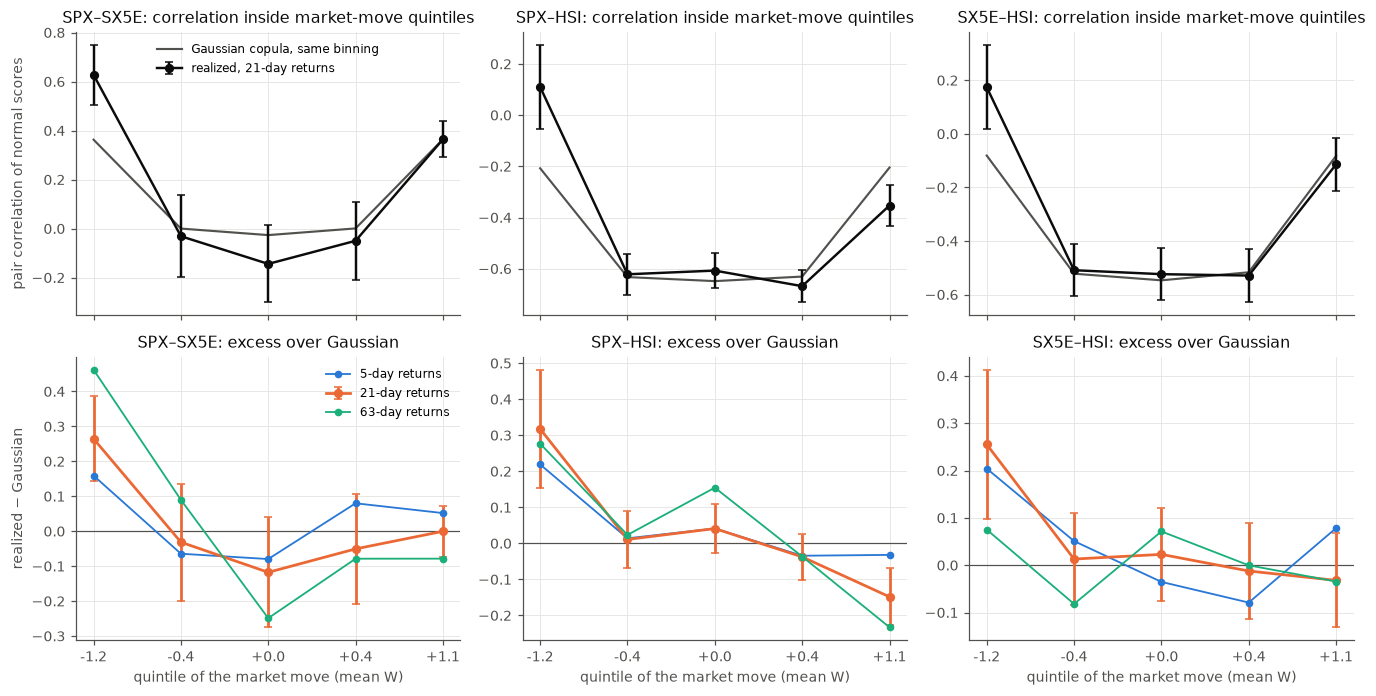

In [2]:
rng = np.random.default_rng(0)
real, excess, sd, wmean, gauss, half = {}, {}, {}, {}, {}, {}
for h in HORIZONS:
    r = lr.diff(h).dropna().values
    z = scores(r)
    real[h], wmean[h] = binned_corr(z)
    half[h] = half_split(z)
    n, blk = len(r), 126
    boots = []
    for _ in range(400):
        st = rng.integers(0, n - blk, size=n // blk + 1)
        idx = np.concatenate([np.arange(s, s + blk) for s in st])[:n]
        boots.append(binned_corr(scores(r[idx]))[0])
    sd[h] = np.array(boots).std(0)
    c_rank = np.corrcoef(z.T)
    gauss[h] = binned_corr(rng.standard_normal((2 ** 18, 3)) @ np.linalg.cholesky(c_rank).T)[0]
    excess[h] = real[h] - gauss[h]

xb = np.arange(5)
xlab = [f"{w:+.1f}" for w in wmean[21]]
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.4), sharex=True)
for i, lab in enumerate(PAIR_LAB):
    ax = axes[0, i]
    ax.plot(xb, gauss[21][:, i], color=INK2, lw=1.4, label="Gaussian copula, same binning")
    ax.errorbar(xb, real[21][:, i], yerr=sd[21][:, i], color=INK, lw=1.6, marker="o", ms=5,
                capsize=2.5, label="realized, 21-day returns")
    ax.set_title(f"{lab}: correlation inside market-move quintiles")
    ax = axes[1, i]
    ax.axhline(0, color=INK2, lw=0.8)
    for k, (h, col) in enumerate(zip(HORIZONS, PAL[:3])):
        ax.errorbar(xb, excess[h][:, i], yerr=sd[h][:, i] if h == 21 else None, color=col,
                    lw=1.8 if h == 21 else 1.2, marker="o", ms=5 if h == 21 else 4, capsize=2.5,
                    label=f"{h}-day returns")
    ax.set_title(f"{lab}: excess over Gaussian")
    ax.set_xticks(xb, xlab)
    ax.set_xlabel("quintile of the market move (mean W)")
axes[0, 0].set_ylabel("pair correlation of normal scores")
axes[1, 0].set_ylabel("realized − Gaussian")
axes[0, 0].legend(loc="upper center", fontsize=8)
axes[1, 0].legend(loc="upper right", fontsize=8)
plt.tight_layout()

tab = pd.DataFrame({"bin mean W": np.round(wmean[21], 2),
                    **{f"{lab} excess": np.round(excess[21][:, i], 2) for i, lab in enumerate(PAIR_LAB)},
                    **{f"{lab} sd": np.round(sd[21][:, i], 2) for i, lab in enumerate(PAIR_LAB)}})
tab.index.name = "21-day quintile"
display(tab)
hs = pd.DataFrame({f"{h}d down": half[h][0] for h in HORIZONS} | {f"{h}d up": half[h][1] for h in HORIZONS},
                  index=PAIR_LAB)
hs.loc["mean over pairs"] = hs.mean()
hs.loc["mean down − up"] = [np.mean(half[h][0] - half[h][1]) for h in HORIZONS] + [np.nan] * 3
print("half-sample correlations (split on the sign of the market move):")
hs.round(2)

**What the history says.** Three features, consistent across horizons:

- **The middle 60% of market moves is Gaussian.** Bins 1–3 sit on the
  benchmark within noise on every pair, at every horizon.
- **The worst quintile carries the asymmetry, on every pair.** At 21 days the
  excess is +0.26 / +0.32 / +0.26 (sd 0.12–0.16); at 63 days similar or
  larger, at 5 days smaller (+0.16 to +0.22 — the asynchronous Asian/US
  close still blurs 5-day co-movement).
- **The best quintile is Gaussian for SPX–SX5E and below Gaussian for the
  HSI pairs** (−0.15 on SPX–HSI at 21 days, 2 sd). Rallies de-correlate
  Hong Kong from the West; they do not de-correlate Europe from the US.

So the profile to fit is **a plateau with a down-tail lift and an HSI-only
up-tail dip** — not the symmetric "high when down, low when up" picture a
single centred tanh encodes. The half-sample split (bottom table) is the
one-number summary used later as a plausibility check: SPX–SX5E 0.59 in down
markets vs 0.45 in up markets at 21 days.

## B. Candidate profiles

Six candidates, fixed colours throughout the notebook. The three step models
and the tanh come from the (ρ_down, ρ_up) grid study; the two sigmoids are
the least-squares fits to the binned 21-day profile (bootstrap-sd weighted,
unconditional level pinned), one per level convention.

| # | candidate | built on | what it assumes |
|---|---|---|---|
| 1 | step 0.85 / 0.65 | 5-day matrix, level held | SPX–SX5E 0.85 when W < 0, 0.65 when W > 0 |
| 2 | step 0.90 / 0.60 | 5-day matrix, level held | the row whose half-split asymmetry matched the history |
| 3 | step 0.85 / 0.55 beyond +0.5σ | 5-day matrix, level held | low correlation only in a strong rally |
| 4 | tanh λ = 0.3 | 5-day loadings | correlation → 1 in sell-offs, 0.45 at +1σ |
| 5 | sigmoid, Pearson-pinned | 21-day Pearson matrix (0.82) | shape fit to the 21-day bins, level = the Gaussian-21d row |
| 6 | sigmoid, rank-fit | 21-day normal scores (0.74) | level *and* shape fit to the 21-day bins |

profile_21d  λ_dn [0.23 0.01 0.5 ]  λ_up [0.   0.   0.28]  c_dn -0.96  c_up +0.30  width 0.16  plateau loadings [0.786 0.99  0.483]  χ² 3.7
profile_rank λ_dn [0.39 0.04 0.54]  λ_up [0.01 0.   0.32]  c_dn -1.41  c_up +0.32  width 0.16  plateau loadings [0.731 0.957 0.522]  χ² 2.7


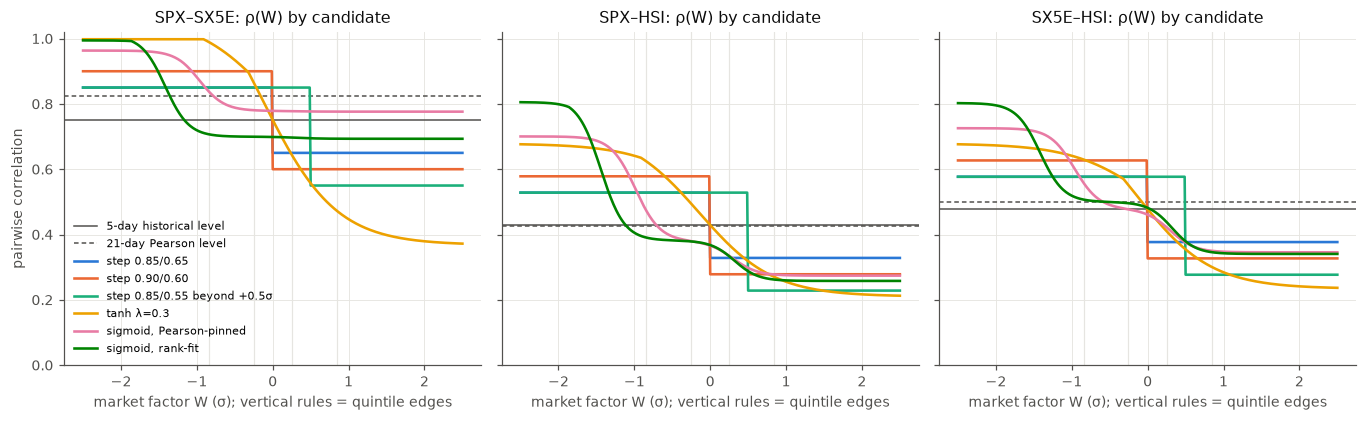

In [3]:
c5 = historical_corr(spots, 5).values
c21 = historical_corr(spots, 21).values
c_rank21 = np.corrcoef(scores(lr.diff(21).dropna().values).T)
a5, a21, a_rank = one_factor_loadings(c5), one_factor_loadings(c21), one_factor_loadings(c_rank21)

def shifted(c, delta):
    out = np.array(c, dtype=float)
    for i, j in PAIRS:
        out[i, j] = out[j, i] = c[i, j] + delta
    return out

def step(rho_dn, rho_up, theta=0.0):
    a_dn = one_factor_loadings(shifted(c5, rho_dn - c5[0, 1]))
    a_up = one_factor_loadings(shifted(c5, rho_up - c5[0, 1]))
    return step_profile(a_dn, a_up, theta), (theta,)

def sigmoid_from_fit(key):
    f = fit[key]
    return (sigmoid_profile(np.array(f["a"]), f["lam_dn"], f["lam_up"], f["c_dn"], f["c_up"], f["width"]),
            (f["c_dn"], f["c_up"]))

CANDS = {  # name -> (profile, breaks, constant-profile benchmark loadings, colour)
    "step 0.85/0.65": (*step(0.85, 0.65), a5, PAL[0]),
    "step 0.90/0.60": (*step(0.90, 0.60), a5, PAL[1]),
    "step 0.85/0.55 beyond +0.5σ": (*step(0.85, 0.55, 0.5), a5, PAL[2]),
    "tanh λ=0.3": (tanh_profile(a5, 0.3), (), a5, PAL[3]),
    "sigmoid, Pearson-pinned": (*sigmoid_from_fit("profile_21d"), a21, PAL[4]),
    "sigmoid, rank-fit": (*sigmoid_from_fit("profile_rank"), a_rank, PAL[5]),
}
for key in ("profile_21d", "profile_rank"):
    f = fit[key]
    print(f"{key:12s} λ_dn {np.round(f['lam_dn'], 2)}  λ_up {np.round(f['lam_up'], 2)}  c_dn {f['c_dn']:+.2f}  "
          f"c_up {f['c_up']:+.2f}  width {f['width']:.2f}  plateau loadings {np.round(f['a'], 3)}  χ² {f['chi2_bins']:.1f}")

wg = np.linspace(-2.5, 2.5, 401)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharey=True)
for i, ((p, q), lab) in enumerate(zip(PAIRS, PAIR_LAB)):
    ax = axes[i]
    for e in norm.ppf([0.2, 0.4, 0.6, 0.8]):
        ax.axvline(e, color=GRID, lw=0.8)
    ax.axhline(c5[p, q], color=INK2, lw=1.0, label="5-day historical level" if i == 0 else None)
    ax.axhline(c21[p, q], color=INK2, lw=1.0, ls=(0, (3, 2)), label="21-day Pearson level" if i == 0 else None)
    for name, (pf, br, _, col) in CANDS.items():
        ax.plot(wg, pf(wg, p) * pf(wg, q), color=col, lw=1.7, label=name if i == 0 else None)
    ax.set_title(f"{lab}: ρ(W) by candidate")
    ax.set_xlabel("market factor W (σ); vertical rules = quintile edges")
axes[0].set_ylabel("pairwise correlation")
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=7.5, loc="lower left")
plt.tight_layout()

,χ² raw bins (15),χ² shape only (15),SPX–SX5E unconditional,SPX–SX5E down half,SPX–SX5E up half,mean down − up
"realized, 21-day",0.00,0.00,0.74,0.59,0.45,0.19
"sigmoid, rank-fit",2.76,2.78,0.74,0.59,0.44,0.22
step 0.85/0.65,11.62,10.47,0.75,0.62,0.43,0.14
"sigmoid, Pearson-pinned",13.40,3.74,0.82,0.72,0.58,0.21
step 0.90/0.60,13.75,12.77,0.76,0.68,0.39,0.20
step 0.85/0.55 beyond +0.5σ,15.23,14.39,0.75,0.64,0.39,0.19
"Gaussian, 5-day matrix",17.75,16.14,0.75,0.51,0.51,0.00
tanh λ=0.3,41.78,40.31,0.74,0.79,0.25,0.34


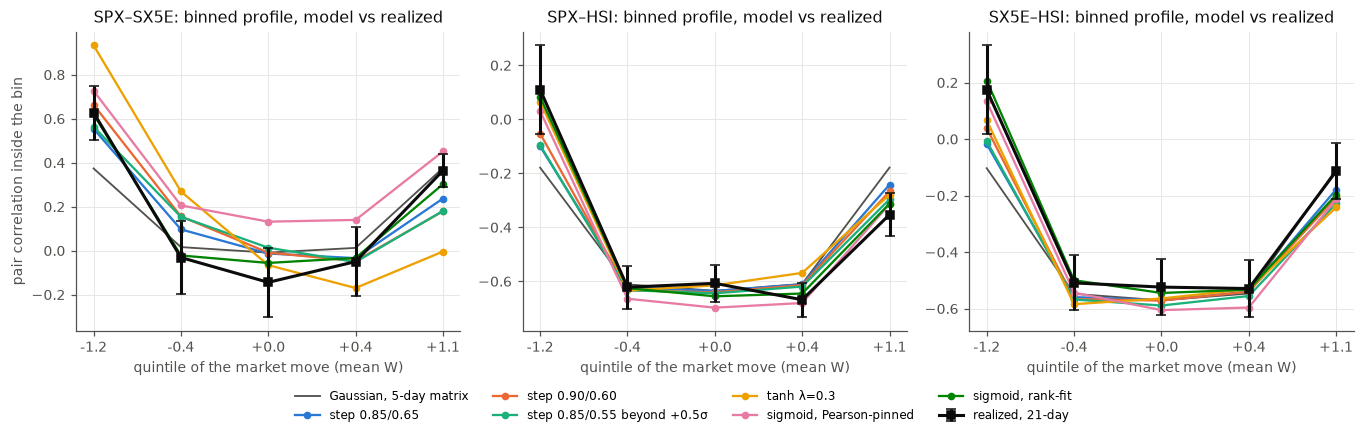

In [4]:
pts = qmc.Sobol(d=4, scramble=True, seed=11).random_base2(17)
model_bins, model_half, model_unc, chi_raw, chi_shape = {}, {}, {}, {}, {}
for name, (pf, br, a_bench, col) in CANDS.items():
    z = norm.ppf(profile_uniforms(pts, pf, br))
    b, _ = binned_corr(z)
    z0 = norm.ppf(profile_uniforms(pts, step_profile(a_bench, a_bench), ()))
    b0, _ = binned_corr(z0)
    model_bins[name], model_half[name], model_unc[name] = b, half_split(z), pair_corr(z)
    chi_raw[name] = np.sum(((b - real[21]) / sd[21]) ** 2)
    chi_shape[name] = np.sum((((b - b0) - excess[21]) / sd[21]) ** 2)
z0 = norm.ppf(profile_uniforms(pts, step_profile(a5, a5), ()))
b_g5, _ = binned_corr(z0)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), sharex=True)
for i, lab in enumerate(PAIR_LAB):
    ax = axes[i]
    ax.plot(xb, b_g5[:, i], color=INK2, lw=1.2, label="Gaussian, 5-day matrix" if i == 0 else None)
    for name, (pf, br, _, col) in CANDS.items():
        ax.plot(xb, model_bins[name][:, i], color=col, lw=1.5, marker="o", ms=4, label=name if i == 0 else None)
    ax.errorbar(xb, real[21][:, i], yerr=sd[21][:, i], color=INK, lw=2.0, marker="s", ms=5.5, capsize=3,
                label="realized, 21-day" if i == 0 else None, zorder=5)
    ax.set_title(f"{lab}: binned profile, model vs realized")
    ax.set_xticks(xb, xlab)
    ax.set_xlabel("quintile of the market move (mean W)")
axes[0].set_ylabel("pair correlation inside the bin")
fig.legend(loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.08, 1, 1))

fitt = pd.DataFrame({
    "χ² raw bins (15)": chi_raw, "χ² shape only (15)": chi_shape,
    "SPX–SX5E unconditional": {k: v[0] for k, v in model_unc.items()},
    "SPX–SX5E down half": {k: v[0][0] for k, v in model_half.items()},
    "SPX–SX5E up half": {k: v[1][0] for k, v in model_half.items()},
    "mean down − up": {k: np.mean(v[0] - v[1]) for k, v in model_half.items()},
})
fitt.loc["Gaussian, 5-day matrix"] = [np.sum(((b_g5 - real[21]) / sd[21]) ** 2),
                                      np.sum((excess[21] / sd[21]) ** 2), c5[0, 1],
                                      *half_split(z0)[0][:1], *half_split(z0)[1][:1], 0.0]
fitt.loc["realized, 21-day"] = [0, 0, c_rank21[0, 1], half[21][0][0], half[21][1][0], np.mean(half[21][0] - half[21][1])]
fitt.sort_values("χ² raw bins (15)").round(2)

**Which fits the history better.** Two chi-squares: *raw* compares each
candidate's binned correlations with the realized ones directly (so it
penalises a wrong level); *shape* compares each candidate's excess over its
own constant-profile benchmark with the realized excess (level removed).

- **The rank-fit sigmoid is the only candidate that matches the history on
  both counts** — raw χ² ≈ 3 on 15 bins and the half-split reproduced to
  the second decimal (0.59 | 0.44 vs 0.59 | 0.45). Its SPX–SX5E profile:
  ≈1.0 below −2σ, 0.89 at −1.5σ, 0.72 at −1σ, a 0.70 plateau, 0.69 in
  rallies; the HSI pairs fall from ≈0.8 in a deep sell-off to 0.26–0.34
  above +0.5σ.
- **The Pearson-pinned sigmoid has the same shape but sits ~0.08 too high
  everywhere outside the crash** — the price of pinning the level to a
  Pearson number the ranks do not support. Shape χ² is as good as the
  rank fit; raw χ² is not.
- **The steps sit in between (χ² 12–15).** 0.90 / 0.60 reproduces the
  half-split asymmetry (+0.20 vs +0.19 realized) and 0.85 / 0.65 edges it on
  the bins, but every step puts the asymmetry in the wrong place: a step at
  W = 0 lifts the whole down half and cuts the whole up half, where the data
  want the middle untouched and the lift concentrated below −1σ. Moving the
  threshold into the rally (0.85 / 0.55 beyond +0.5σ) does not help.
- **The tanh overshoots on every axis**: perfect correlation in any sell-off
  worse than 1σ, a down-half correlation of 0.79 against 0.59 realized, and
  an asymmetry twice the data's. It is a bound on what asymmetric dependence
  can do, not a calibration.

## C. Price impact

ATM call (strike 100%), cap call (112%) and their difference, the call spread
the insurer buys, priced on 2^20 common-random-number Sobol paths with each
candidate copula and the same implied marginals; four as-of dates spanning
the vol regimes. The bank gap to explain is **ATM +25 / cap −25 / package
+50 bps of notional** (bank minus model). All moves below are relative to the
existing baseline, the Gaussian copula on the 5-day matrix.

In [5]:
QUOTE = "2026-07-31"
pq = prof[prof.date == QUOTE].set_index("row")
rq = regime[regime.date == QUOTE]
def grid_row(variant, theta, rd, ru, lam=0.0):
    m = (rq.variant == variant) & np.isclose(rq.theta, theta) & np.isclose(rq.lam, lam)
    if variant != "tanh":
        m &= np.isclose(rq.rho_dn, rd) & np.isclose(rq.rho_up, ru)
    return rq[m].iloc[0]

price_rows = {
    "Gaussian, 5-day matrix (existing baseline)": pq.loc["gauss_5d"],
    "Gaussian, 21-day Pearson matrix": pq.loc["gauss_21d"],
    "step 0.85/0.65": grid_row("all", 0.0, 0.85, 0.65),
    "step 0.90/0.60": grid_row("all", 0.0, 0.90, 0.60),
    "step 0.85/0.55 beyond +0.5σ": grid_row("all", 0.5, 0.85, 0.55),
    "tanh λ=0.3": grid_row("tanh", 0.0, None, None, 0.3),
    "sigmoid, Pearson-pinned": pq.loc["profile_21d"],
    "sigmoid, rank-fit": pq.loc["profile_rank"],
}
pt = pd.DataFrame({name: {"ATM (bps)": r["atm"], "cap (bps)": r["cap"], "package (bps)": r["spread"],
                          "ΔATM": r["d_atm"], "Δcap": r["d_cap"], "Δpackage": r["d_spread"],
                          "share of ATM gap": r["d_atm"] / 25, "share of cap gap": r["d_cap"] / -25,
                          "share of package gap": r["d_spread"] / 50}
                   for name, r in price_rows.items()}).T
pt["χ² raw bins"] = [fitt.loc["Gaussian, 5-day matrix", "χ² raw bins (15)"], np.nan,
                     *[chi_raw[k] for k in list(CANDS)]]
pt.loc["bank quote (gap to explain)"] = [np.nan, np.nan, np.nan, 25, -25, 50, 1, 1, 1, np.nan]
print(f"{QUOTE}: moves vs the existing baseline, bps of notional")
pt.round(2)

2026-07-31: moves vs the existing baseline, bps of notional


,ATM (bps),cap (bps),package (bps),ΔATM,Δcap,Δpackage,share of ATM gap,share of cap gap,share of package gap,χ² raw bins
"Gaussian, 5-day matrix (existing baseline)",751.29,221.19,530.11,0.00,0.00,0.00,0.00,-0.00,0.00,17.75
"Gaussian, 21-day Pearson matrix",753.38,224.35,529.03,2.09,3.16,-1.08,0.08,-0.13,-0.02,NaN
step 0.85/0.65,757.95,218.50,539.46,6.62,-2.73,9.35,0.26,0.11,0.19,11.62
step 0.90/0.60,761.26,216.98,544.28,9.92,-4.24,14.17,0.40,0.17,0.28,13.75
step 0.85/0.55 beyond +0.5σ,760.04,211.94,548.10,8.71,-9.28,17.99,0.35,0.37,0.36,15.23
tanh λ=0.3,771.40,211.03,560.37,20.07,-10.19,30.26,0.80,0.41,0.61,41.78
"sigmoid, Pearson-pinned",759.63,216.07,543.56,8.34,-5.11,13.45,0.33,0.20,0.27,13.40
"sigmoid, rank-fit",752.86,210.89,541.97,1.57,-10.29,11.86,0.06,0.41,0.24,2.76
bank quote (gap to explain),NaN,NaN,NaN,25.00,-25.00,50.00,1.00,1.00,1.00,NaN


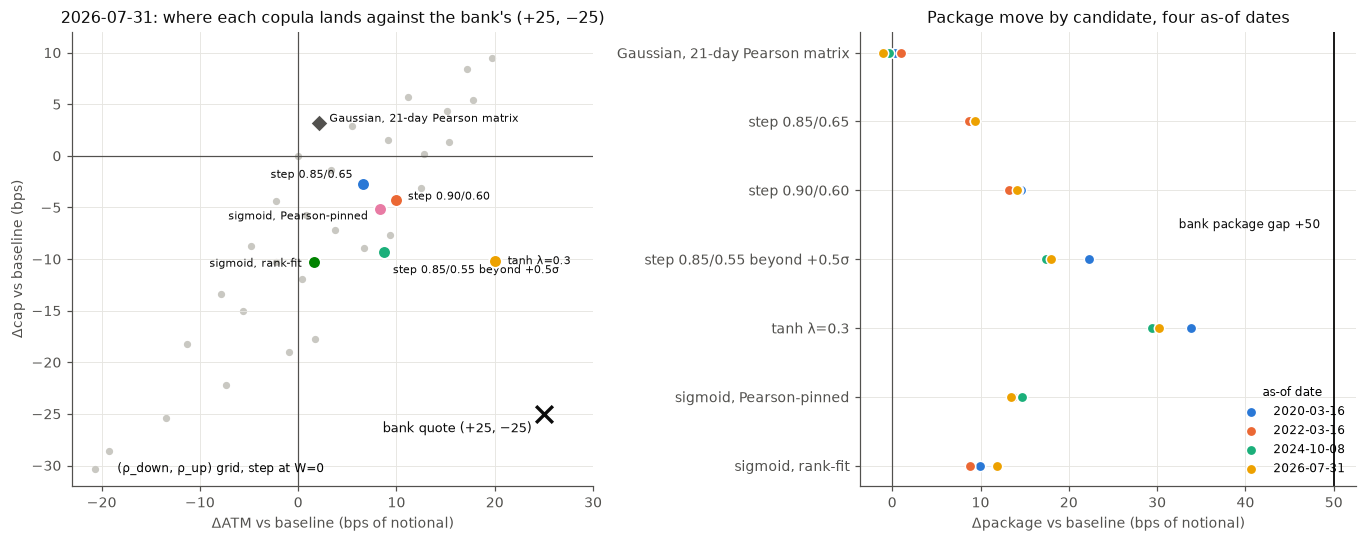

In [6]:
grid0 = rq[(rq.variant == "all") & (rq.theta == 0)]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.0), gridspec_kw={"width_ratios": [1.05, 1]})
ax.axhline(0, color=INK2, lw=0.8); ax.axvline(0, color=INK2, lw=0.8)
ax.scatter(grid0.d_atm, grid0.d_cap, s=14, color="#c9c8c2", label="(ρ_down, ρ_up) grid, step at W=0")
OFFS = {"Gaussian, 21-day Pearson matrix": (7, 3, "left"), "step 0.85/0.65": (-7, 6, "right"),
        "step 0.90/0.60": (8, 2, "left"), "sigmoid, Pearson-pinned": (-8, -5, "right"),
        "step 0.85/0.55 beyond +0.5σ": (6, -12, "left"), "sigmoid, rank-fit": (-8, -1, "right"),
        "tanh λ=0.3": (8, 0, "left")}
for name, r in price_rows.items():
    if name.startswith("Gaussian, 5"):
        continue
    col = CANDS[name][3] if name in CANDS else INK2
    mk = "o" if name in CANDS else "D"
    ax.scatter(r["d_atm"], r["d_cap"], s=70, color=col, marker=mk, edgecolor="white", linewidth=1.2, zorder=4)
    dx, dy, ha = OFFS[name]
    ax.annotate(name, (r["d_atm"], r["d_cap"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=7.5, color=INK, ha=ha, va="center")
ax.scatter([25], [-25], s=120, color=INK, marker="x", linewidth=2.2, zorder=5)
ax.annotate("bank quote (+25, −25)", (25, -25), xytext=(-8, -12), textcoords="offset points", fontsize=8.5,
            color=INK, ha="right")
ax.set(xlabel="ΔATM vs baseline (bps of notional)", ylabel="Δcap vs baseline (bps)", xlim=(-23, 30), ylim=(-32, 12),
       title=f"{QUOTE}: where each copula lands against the bank's (+25, −25)")
ax.legend(loc="lower left", fontsize=8)

order = [n for n in price_rows if not n.startswith("Gaussian, 5")]
key_map = {"Gaussian, 21-day Pearson matrix": ("profile", "gauss_21d"), "sigmoid, Pearson-pinned": ("profile", "profile_21d"),
           "sigmoid, rank-fit": ("profile", "profile_rank"), "step 0.85/0.65": ("regime", ("all", 0.0, 0.85, 0.65, 0.0)),
           "step 0.90/0.60": ("regime", ("all", 0.0, 0.90, 0.60, 0.0)),
           "step 0.85/0.55 beyond +0.5σ": ("regime", ("all", 0.5, 0.85, 0.55, 0.0)),
           "tanh λ=0.3": ("regime", ("tanh", 0.0, None, None, 0.3))}
DATES = ["2020-03-16", "2022-03-16", "2024-10-08", "2026-07-31"]
for k, (d, col) in enumerate(zip(DATES, PAL[:4])):
    ys, xs = [], []
    for i, name in enumerate(order):
        src, key = key_map[name]
        if src == "profile":
            v = prof[(prof.date == d) & (prof.row == key)].d_spread.iloc[0]
        else:
            rd_ = regime[regime.date == d]
            m = (rd_.variant == key[0]) & np.isclose(rd_.theta, key[1]) & np.isclose(rd_.lam, key[4])
            if key[0] != "tanh":
                m &= np.isclose(rd_.rho_dn, key[2]) & np.isclose(rd_.rho_up, key[3])
            v = rd_[m].d_spread.iloc[0]
        xs.append(v); ys.append(i)
    ax2.scatter(xs, ys, s=46, color=col, edgecolor="white", linewidth=1.0, label=d, zorder=3)
ax2.axvline(0, color=INK2, lw=0.8)
ax2.axvline(50, color=INK, lw=1.2)
ax2.text(48.5, 2.5, "bank package gap +50", fontsize=8, color=INK, ha="right", va="center")
ax2.set_yticks(range(len(order)), order)
ax2.invert_yaxis()
ax2.set(xlabel="Δpackage vs baseline (bps of notional)", title="Package move by candidate, four as-of dates")
ax2.legend(loc="lower right", fontsize=8, title="as-of date", title_fontsize=8)
plt.tight_layout()

slopes per +0.10 of ρ_down: ATM +11.2, cap +5.7 bps;  per −0.10 of ρ_up: ATM -4.8, cap -8.8 bps
notebook runtime 9.3s


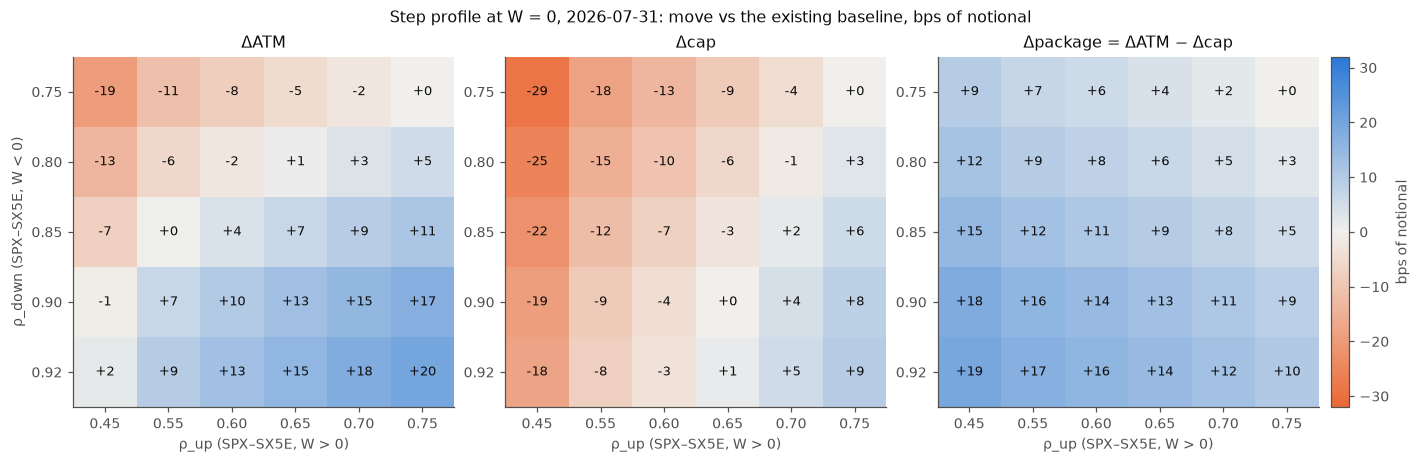

In [7]:
piv = {leg: grid0.pivot(index="rho_dn", columns="rho_up", values=f"d_{leg}") for leg in ("atm", "cap", "spread")}
cmap = LinearSegmentedColormap.from_list("div", [PAL[1], "#f1f0ec", PAL[0]])
fig, axes = plt.subplots(1, 3, figsize=(12.8, 4.1), constrained_layout=True)
fig.suptitle(f"Step profile at W = 0, {QUOTE}: move vs the existing baseline, bps of notional", fontsize=10.5, color=INK)
for ax, (leg, title) in zip(axes, [("atm", "ΔATM"), ("cap", "Δcap"), ("spread", "Δpackage = ΔATM − Δcap")]):
    m = piv[leg]
    im = ax.imshow(m.values, cmap=cmap, norm=TwoSlopeNorm(0, -32, 32), aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:+.0f}", ha="center", va="center", fontsize=8.5, color=INK)
    ax.set_xticks(range(m.shape[1]), [f"{c:.2f}" for c in m.columns])
    ax.set_yticks(range(m.shape[0]), [f"{r:.2f}" for r in m.index])
    ax.set(xlabel="ρ_up (SPX–SX5E, W > 0)", title=title)
    ax.grid(False)
axes[0].set_ylabel("ρ_down (SPX–SX5E, W < 0)")
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.01, label="bps of notional")
slope_dn = (piv["atm"].loc[0.85, 0.751] - piv["atm"].loc[0.751, 0.751]) / 0.1, (piv["cap"].loc[0.85, 0.751] - piv["cap"].loc[0.751, 0.751]) / 0.1
slope_up = (piv["atm"].loc[0.751, 0.65] - piv["atm"].loc[0.751, 0.751]) / -0.1, (piv["cap"].loc[0.751, 0.65] - piv["cap"].loc[0.751, 0.751]) / -0.1
print(f"slopes per +0.10 of ρ_down: ATM {slope_dn[0] * .1:+.1f}, cap {slope_dn[1] * .1:+.1f} bps;  "
      f"per −0.10 of ρ_up: ATM {slope_up[0] * -.1:+.1f}, cap {slope_up[1] * -.1:+.1f} bps")
print(f"notebook runtime {time.time() - T0:.1f}s")

**What the prices say.**

- **Both legs are long correlation; asymmetry only redistributes.** Raising
  the down-side correlation by 0.10 lifts the ATM +11 and the cap +6;
  lowering the up-side by 0.10 cuts them −5 and −9. The ATM-up / cap-down
  wedge is the *difference* of those slopes — the ATM's dispersion exposure
  through the 0.5 / 0.3 rank weights — so the heatmap's "right-sign" region
  is a thin band around the level-neutral anti-diagonal, and extrapolating
  the slopes to (+25, −25) needs ρ_down ≈ 1.26. The target is outside the
  model's reach, not just outside the data's.
- **The history-calibrated profile buys about a quarter of the package gap,
  on every date**: +9 to +15 bps of the +50 depending on date and level
  convention, the same size as the 0.85 / 0.65 and 0.90 / 0.60 steps it
  resembles in asymmetry. Switching the Gaussian from 5-day to
  21-day correlation does nothing for the package (both legs +2 to +3 bps).
- **Which leg gets it is the level convention, not the data.** Pinned to the
  21-day Pearson level the sigmoid moves ATM +8 / cap −5 (shape alone, vs the
  Gaussian-21d row: +6 / −8). Fit to the ranks, its plateau sits at 0.70 —
  below the baseline's 0.75 — so the ATM gives back what the down-tail lift
  adds and the cap takes the whole move: ATM +2 / cap −10.
- **Three quarters of the bank's +25 / −25 is not dependence.** After the
  most history-faithful copula so far, ~15–23 bps per leg remain, about
  0.4–0.65 vol points at the legs' vegas of 38 and 34 bps per basket-vol
  point: a per-leg bid/offer, to be calibrated across banks and dates rather
  than modelled.

Caveats: the dependence is measured at 21 days (≈94 independent windows,
tail-bin sd 0.12–0.17) and applied to one-year performances; the marginals
are the vendor surfaces as-is; no FX or quanto.